<a href="https://colab.research.google.com/github/AntonyMorenoCod/Taller-semana-8-MachineLearning/blob/main/Taller_Semana_8_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Actividad: Implementación y comparación de algoritmo de clasificación

**Introducción a Machine Learning**

Ferley Antonio Moreno Cruz

In [ ]:
# Importar librerías fundamentales para manejo de datos
import pandas as pd
import numpy as np
from sklearn import datasets

# 1. Cargar el dataset de vinos integrado en scikit-learn
wine = datasets.load_wine()

# 2. Definir las variables de entrada (X) y la variable objetivo (y)
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='target')

# 3. Exploración inicial del conjunto de datos
print("=== DIMENSIONES DEL CONJUNTO DE DATOS ===")
print(f"Total de muestras (filas): {X.shape[0]}")
print(f"Total de variables de entrada (columnas): {X.shape[1]}\n")

print("=== CLASES DE LA VARIABLE OBJETIVO (y) ===")
for i, nombre_clase in enumerate(wine.target_names):
    conteo = (y == i).sum()
    print(f"Clase {i} ({nombre_clase}): {conteo} muestras")

print("\n=== PRIMERAS 5 FILAS DE LAS VARIABLES DE ENTRADA (X) ===")
display(X.head())

=== DIMENSIONES DEL CONJUNTO DE DATOS ===
Total de muestras (filas): 178
Total de variables de entrada (columnas): 13

=== CLASES DE LA VARIABLE OBJETIVO (y) ===
Clase 0 (class_0): 59 muestras
Clase 1 (class_1): 71 muestras
Clase 2 (class_2): 48 muestras

=== PRIMERAS 5 FILAS DE LAS VARIABLES DE ENTRADA (X) ===


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 2. Preparación de Datos y División del Conjunto (Train / Test)
Antes de entrenar los algoritmos de clasificación, se realiza el preprocesamiento de los datos siguiendo tres etapas fundamentales:

1. **Verificación de calidad de datos:** Se comprueba la ausencia de valores nulos o faltantes en las 13 características.
2. **División en conjuntos de entrenamiento y prueba (`train_test_split`):** Se separa el 70% de los datos para entrenar los modelos y el 30% restante para evaluarlos. Se fija una semilla de aleatoriedad (`random_state=42`) y se aplica muestreo estratificado (`stratify=y`) para conservar la misma proporción de las tres clases de vino en ambos subconjuntos. Este único conjunto dividido se utilizará exactamente igual para los cinco algoritmos.
3. **Escalado de características (`StandardScaler`):** Dado que variables como `proline` (rango > 1000) y `nonflavanoid_phenols` (rango < 1) manejan magnitudes muy distintas, se estandarizan los datos (media = 0 y desviación estándar = 1). Esto evita que las variables con números grandes dominen algoritmos sensibles a la escala y a las distancias como **SVM** y **K-NN**. Para evitar fuga de datos (*data leakage*), el escalador se ajusta únicamente con los datos de entrenamiento (`fit_transform`) y luego se aplica a los de prueba (`transform`).


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Verificar que no existan valores nulos en el conjunto de datos
print("=== VERIFICACIÓN DE VALORES NULOS ===")
print(f"Total de valores nulos en X: {X.isnull().sum().sum()}")
print(f"Total de valores nulos en y: {y.isnull().sum()}\n")

# 2. Dividir los datos en entrenamiento (70%) y prueba (30%)
# Usamos stratify=y para mantener la proporción de clases y random_state=42 para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("=== DIMENSIONES DE ENTRENAMIENTO Y PRUEBA ===")
print(f"Conjunto de entrenamiento (X_train): {X_train.shape[0]} muestras")
print(f"Conjunto de prueba (X_test): {X_test.shape[0]} muestras\n")

# 3. Escalar las variables de entrada (Estandarización)
scaler = StandardScaler()

# Ajustamos con X_train y transformamos ambos conjuntos
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertimos de nuevo a DataFrame solo para visualizar cómo quedaron escalados
df_scaled_preview = pd.DataFrame(X_train_scaled, columns=X.columns)
print("=== VISTA PREVIA DE DATOS ESCALADOS (PRIMERAS 3 FILAS) ===")
display(df_scaled_preview.head(3))

=== VERIFICACIÓN DE VALORES NULOS ===
Total de valores nulos en X: 0
Total de valores nulos en y: 0

=== DIMENSIONES DE ENTRENAMIENTO Y PRUEBA ===
Conjunto de entrenamiento (X_train): 124 muestras
Conjunto de prueba (X_test): 54 muestras

=== VISTA PREVIA DE DATOS ESCALADOS (PRIMERAS 3 FILAS) ===


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.982686,-0.527640,0.173598,-1.087543,-0.727661,0.491455,0.791460,-0.596717,0.354587,0.255419,0.857462,0.437825,1.863180
1,0.957937,-0.745511,1.255504,0.839386,0.063252,1.131923,1.306553,-0.596717,1.343233,0.297587,1.032095,0.159563,1.749108
2,0.401078,-0.612894,1.777803,-1.235769,0.656436,0.491455,0.707363,-0.170491,-0.425924,-0.166255,0.595512,0.262081,0.429136


## 3. Implementación y Evaluación de Modelos de Clasificación
Para garantizar una comparación justa y estandarizada entre los cinco algoritmos, se define una estructura de evaluación común sobre el conjunto de prueba (`X_test_scaled`, `y_test`). En problemas multiclase, las métricas globales de **Precision**, **Recall** y **F1-Score** se calculan mediante el promedio ponderado (`average='weighted'`), el cual toma en cuenta el número de muestras reales de cada clase.

### 3.1. Árbol de Decisión (Decision Tree)
El algoritmo de Árbol de Decisión divide los datos de forma secuencial mediante reglas jerárquicas de tipo "si-entonces", buscando maximizar la pureza de los nodos resultantes. Es un modelo altamente interpretable visualmente, aunque un árbol individual puede presentar sensibilidad a pequeñas variaciones en los datos de entrenamiento.

=== RESULTADOS: DECISION TREE ===
Accuracy (Exactitud) : 0.9630
Precision (Precisión): 0.9662
Recall (Sensibilidad): 0.9630
F1-Score             : 0.9632

--- Reporte detallado por clase ---
              precision    recall  f1-score   support

     class_0       1.00      0.94      0.97        18
     class_1       0.91      1.00      0.95        21
     class_2       1.00      0.93      0.97        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54



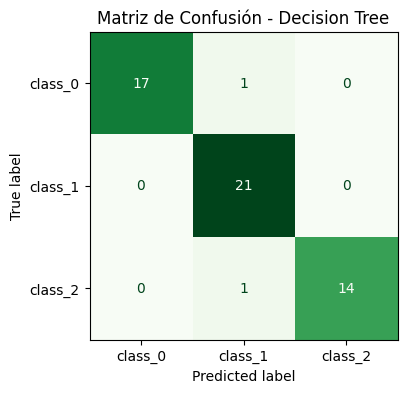

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.tree import DecisionTreeClassifier

# Diccionario para almacenar los resultados de los 5 modelos y compararlos al final
resultados_modelos = {}

# Función auxiliar para evaluar cualquier modelo, mostrar métricas y graficar su Matriz de Confusión
def evaluar_modelo(nombre_modelo, y_real, y_pred, cmap_color='Blues'):
    acc = accuracy_score(y_real, y_pred)
    prec = precision_score(y_real, y_pred, average='weighted')
    rec = recall_score(y_real, y_pred, average='weighted')
    f1 = f1_score(y_real, y_pred, average='weighted')

    # Guardar métricas en el diccionario comparativo
    resultados_modelos[nombre_modelo] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    }

    print(f"=== RESULTADOS: {nombre_modelo.upper()} ===")
    print(f"Accuracy (Exactitud) : {acc:.4f}")
    print(f"Precision (Precisión): {prec:.4f}")
    print(f"Recall (Sensibilidad): {rec:.4f}")
    print(f"F1-Score             : {f1:.4f}\n")

    print("--- Reporte detallado por clase ---")
    print(classification_report(y_real, y_pred, target_names=wine.target_names))

    # Graficar Matriz de Confusión
    cm = confusion_matrix(y_real, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
    disp.plot(cmap=cmap_color, ax=ax, colorbar=False)
    plt.title(f"Matriz de Confusión - {nombre_modelo}")
    plt.show()

# ==========================================
# MODELO 1: DECISION TREE (ÁRBOL DE DECISIÓN)
# ==========================================
# 1. Inicializar y entrenar el modelo (fijamos random_state=42 para reproducibilidad)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# 2. Realizar predicciones sobre el conjunto de prueba
y_pred_dt = dt_model.predict(X_test_scaled)

# 3. Evaluar desempeño y mostrar matriz de confusión
evaluar_modelo("Decision Tree", y_test, y_pred_dt, cmap_color='Greens')

**Interpretación de resultados - Decision Tree:**
* El modelo alcanzó una exactitud (**Accuracy**) del **96.30%** y un **F1-Score** ponderado de **0.9632**, clasificando correctamente 52 de las 54 muestras del conjunto de prueba.
* Al analizar la **Matriz de Confusión**, se observa que la `class_1` logró una sensibilidad (**Recall**) perfecta de **1.00** (21 de 21 aciertos). Sin embargo, su precisión (**Precision**) bajó a **0.91** debido a 2 falsos positivos: el árbol confundió 1 muestra real de `class_0` y 1 muestra de `class_2` asignándolas erróneamente a `class_1`. Esto refleja la sensibilidad típica de un árbol individual frente a fronteras de decisión ajustadas.

---

### 3.2. Bosques Aleatorios (Random Forest)
Random Forest es un método de aprendizaje por ensamble (*ensemble learning*) basado en *bagging* que construye múltiples árboles de decisión entrenados con muestras aleatorias de los datos y subconjuntos aleatorios de variables. Su predicción final se obtiene por votación mayoritaria, lo que reduce la varianza y mitiga el sobreajuste característico de los árboles individuales.

=== RESULTADOS: RANDOM FOREST ===
Accuracy (Exactitud) : 1.0000
Precision (Precisión): 1.0000
Recall (Sensibilidad): 1.0000
F1-Score             : 1.0000

--- Reporte detallado por clase ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



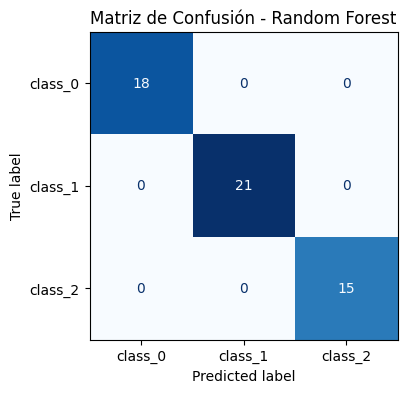

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# ==========================================
# MODELO 2: RANDOM FOREST (BOSQUES ALEATORIOS)
# ==========================================
# 1. Inicializar y entrenar el modelo con 100 árboles (n_estimators=100) y semilla fija
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# 2. Realizar predicciones sobre el conjunto de prueba
y_pred_rf = rf_model.predict(X_test_scaled)

# 3. Evaluar desempeño y mostrar matriz de confusión
evaluar_modelo("Random Forest", y_test, y_pred_rf, cmap_color='Blues')

**Interpretación de resultados - Random Forest:**
* El modelo de ensamble alcanzó una exactitud (**Accuracy**) y un **F1-Score** perfectos de **1.0000 (100%)**, acertando las 54 muestras del conjunto de prueba sin ningún falso positivo ni falso negativo.
* Al comparar su **Matriz de Confusión** frente a la del Árbol de Decisión individual, se comprueba empíricamente la ventaja del *bagging* y la votación mayoritaria: al combinar 100 árboles diversos, el modelo eliminó la varianza y corrigió los 2 errores de clasificación que presentaba el árbol simple en las fronteras de `class_0` y `class_2`.

---

### 3.3. Máquinas de Vectores de Soporte (Support Vector Machine - SVM)
El algoritmo SVM busca encontrar el hiperplano óptimo que maximice el margen de separación entre las diferentes clases en un espacio de alta dimensionalidad. Mediante el uso del "truco del kernel" (como el kernel Gaussiano o RBF), proyecta los datos para trazar fronteras de decisión no lineales complejas. Su rendimiento depende directamente del escalado previo de las variables (`StandardScaler`).

=== RESULTADOS: SVM ===
Accuracy (Exactitud) : 0.9815
Precision (Precisión): 0.9823
Recall (Sensibilidad): 0.9815
F1-Score             : 0.9814

--- Reporte detallado por clase ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       0.95      1.00      0.98        21
     class_2       1.00      0.93      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



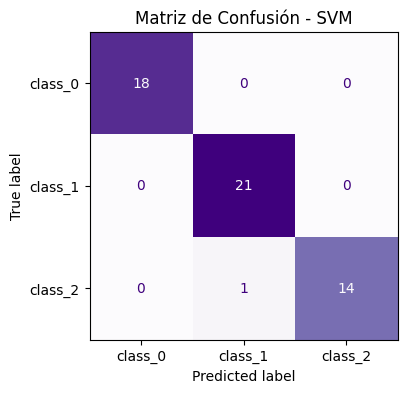

In [ ]:
from sklearn.svm import SVC

# ==========================================
# MODELO 3: SUPPORT VECTOR MACHINE (SVM)
# ==========================================
# 1. Inicializar y entrenar el modelo usando kernel RBF y semilla fija
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 2. Realizar predicciones sobre el conjunto de prueba escalado
y_pred_svm = svm_model.predict(X_test_scaled)

# 3. Evaluar desempeño y mostrar matriz de confusión
evaluar_modelo("SVM", y_test, y_pred_svm, cmap_color='Purples')

**Interpretación de resultados - SVM:**
* El modelo alcanzó una exactitud (**Accuracy**) del **98.15%** y un **F1-Score** de **0.9814**, acertando 53 de las 54 muestras de prueba.
* La **Matriz de Confusión** muestra un desempeño perfecto en `class_0` (Precision = 1.00, Recall = 1.00) y una sensibilidad perfecta en `class_1` (Recall = 1.00). El único error ocurrió en `class_2` (Recall = 0.93), donde 1 muestra fue clasificada como `class_1`. Esto demuestra la alta efectividad del kernel RBF sobre datos previamente estandarizados para separar clases en espacios multidimensionales.

---

### 3.4. K-Vecinos Más Cercanos (K-Nearest Neighbors - K-NN)
K-NN es un algoritmo basado en instancias (aprendizaje perezoso o *lazy learning*) que no construye un modelo matemático explícito durante el entrenamiento, sino que almacena los ejemplos y clasifica cada nueva observación según la clase mayoritaria de sus $K$ vecinos más próximos (calculados mediante distancia euclidiana). Al depender directamente del cálculo de distancias geométricas, el escalado previo de las variables resulta indispensable para evitar sesgos.

=== RESULTADOS: K-NN ===
Accuracy (Exactitud) : 0.9444
Precision (Precisión): 0.9537
Recall (Sensibilidad): 0.9444
F1-Score             : 0.9448

--- Reporte detallado por clase ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.86      0.92        21
     class_2       0.83      1.00      0.91        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54



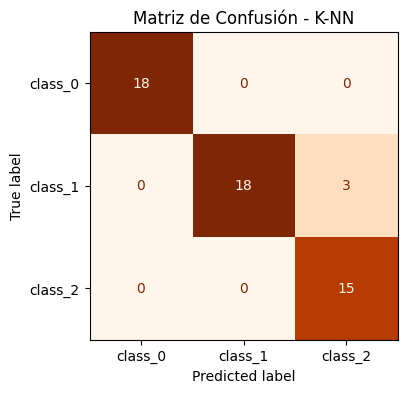

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# ==========================================
# MODELO 4: K-NEAREST NEIGHBORS (K-NN)
# ==========================================
# 1. Inicializar y entrenar el modelo usando K = 5 vecinos (n_neighbors=5)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# 2. Realizar predicciones sobre el conjunto de prueba escalado
y_pred_knn = knn_model.predict(X_test_scaled)

# 3. Evaluar desempeño y mostrar matriz de confusión
evaluar_modelo("K-NN", y_test, y_pred_knn, cmap_color='Oranges')

**Interpretación de resultados - K-NN:**
* El modelo alcanzó una exactitud (**Accuracy**) del **94.44%** y un **F1-Score** de **0.9448**, acertando 51 de las 54 muestras del conjunto de prueba.
* La **Matriz de Confusión** evidencia un desempeño perfecto para identificar las muestras reales de `class_0` (Recall = 1.00) y `class_2` (Recall = 1.00). Sin embargo, en `class_1` la sensibilidad (**Recall**) descendió a **0.86**, ya que 3 muestras reales de `class_1` fueron clasificadas erróneamente como `class_2` (lo que a su vez redujo la **Precision** de `class_2` a **0.83**). Este comportamiento se explica porque K-NN calcula distancias geométricas considerando las 13 variables con igual peso, viéndose levemente afectado en las zonas limítrofes entre las clases 1 y 2.

---

### 3.5. Clasificador Naive Bayes (Gaussian Naive Bayes)
Naive Bayes es un clasificador probabilístico fundamentado en el Teorema de Bayes bajo el supuesto "ingenuo" (*naive*) de independencia condicional entre las variables predictoras dada la clase. Dado que nuestras 13 variables de entrada son químicas y de naturaleza numérica continua, se implementa la variante **Gaussian Naive Bayes (`GaussianNB`)**, la cual asume que los valores de cada característica siguen una distribución normal (gaussiana) dentro de cada categoría de vino.

=== RESULTADOS: NAIVE BAYES ===
Accuracy (Exactitud) : 1.0000
Precision (Precisión): 1.0000
Recall (Sensibilidad): 1.0000
F1-Score             : 1.0000

--- Reporte detallado por clase ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



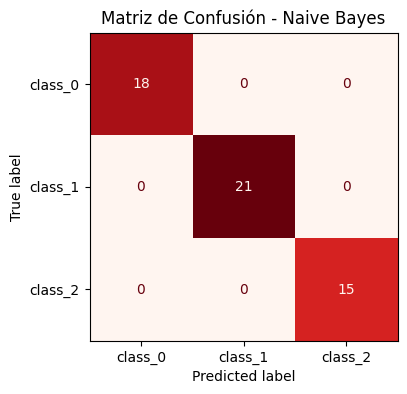

In [ ]:
from sklearn.naive_bayes import GaussianNB

# ==========================================
# MODELO 5: NAIVE BAYES (GAUSSIAN NB)
# ==========================================
# 1. Inicializar y entrenar el modelo probabilístico Gaussiano
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# 2. Realizar predicciones sobre el conjunto de prueba
y_pred_nb = nb_model.predict(X_test_scaled)

# 3. Evaluar desempeño y mostrar matriz de confusión
evaluar_modelo("Naive Bayes", y_test, y_pred_nb, cmap_color='Reds')

**Interpretación de resultados - Naive Bayes:**
* El modelo probabilístico Gaussiano alcanzó un desempeño perfecto en el conjunto de prueba, registrando **1.0000 (100%)** en **Accuracy, Precision, Recall y F1-Score**, sin presentar falsos positivos ni falsos negativos en su Matriz de Confusión.
* A pesar de partir del supuesto "ingenuo" de independencia condicional entre las 13 variables químicas, las distribuciones de probabilidad gaussianas de cada clase están lo suficientemente bien diferenciadas como para permitir una separación exacta y computacionalmente muy veloz en este conjunto de datos.

---

## 4. Comparación de Resultados entre los Cinco Algoritmos
A continuación, se consolidan las métricas obtenidas por cada modelo evaluado sobre exactamente el mismo conjunto de prueba (`54 muestras`), ordenándolos de mayor a menor según su **F1-Score** y **Accuracy**.

=== TABLA COMPARATIVA DE DESEMPEÑO (CONJUNTO DE PRUEBA) ===


,Accuracy,Precision,Recall,F1-Score
Random Forest,1.0000,1.0000,1.0000,1.0000
Naive Bayes,1.0000,1.0000,1.0000,1.0000
SVM,0.9815,0.9823,0.9815,0.9814
Decision Tree,0.9630,0.9662,0.9630,0.9632
K-NN,0.9444,0.9537,0.9444,0.9448


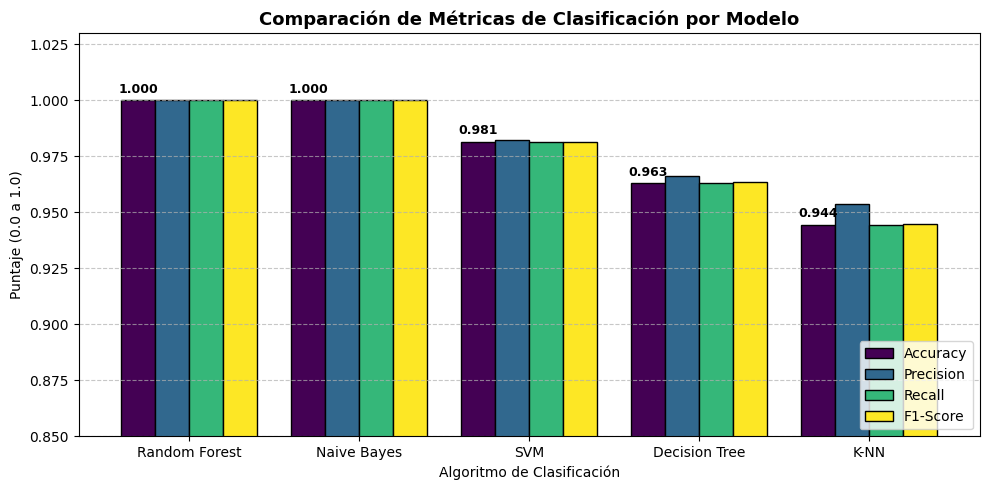

In [ ]:
# 1. Crear DataFrame comparativo a partir del diccionario de resultados
df_comparacion = pd.DataFrame(resultados_modelos).T
df_comparacion = df_comparacion.sort_values(by='F1-Score', ascending=False)

print("=== TABLA COMPARATIVA DE DESEMPEÑO (CONJUNTO DE PRUEBA) ===")
display(df_comparacion.style.format("{:.4f}").background_gradient(cmap='YlGn'))

# 2. Gráfico comparativo de las métricas por modelo
ax = df_comparacion.plot(kind='bar', figsize=(10, 5), width=0.8, colormap='viridis', edgecolor='black')
plt.title('Comparación de Métricas de Clasificación por Modelo', fontsize=13, fontweight='bold')
plt.ylabel('Puntaje (0.0 a 1.0)')
plt.xlabel('Algoritmo de Clasificación')
plt.ylim(0.85, 1.03)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')

# Mostrar valores sobre las barras de Accuracy
for p in ax.patches[:5]:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

## 5. Análisis Comparativo y Justificación de Selección del Modelo

### 5.1. Síntesis Comparativa
1. **Modelos con desempeño sobresaliente (100%):** Tanto **Random Forest** como **Naive Bayes** alcanzaron un `Accuracy` y `F1-Score` de **1.0000** (54/54 aciertos), demostrando una capacidad óptima para separar las tres categorías de vino.
2. **Modelo de margen máximo (98.15%):** **SVM (Kernel RBF)** logró el tercer mejor lugar con **0.9815** de `Accuracy` y **0.9814** de `F1-Score`, cometiendo apenas 1 error de clasificación (una muestra de `class_2` predicha como `class_1`).
3. **Modelo basado en reglas simples (96.30%):** El **Árbol de Decisión (Decision Tree)** obtuvo un `Accuracy` de **0.9630** y `F1-Score` de **0.9632** (2 errores en total), evidenciando cómo un árbol individual es ligeramente más propenso a la varianza que el ensamble completo de Random Forest.
4. **Modelo basado en distancias (94.44%):** **K-NN ($K=5$)** ocupó el quinto lugar con un `Accuracy` de **0.9444** y `F1-Score` de **0.9448** (3 errores de `class_1` clasificados como `class_2`), debido a que en un espacio de 13 dimensiones la distancia euclidiana pondera por igual todas las variables, incluyendo aquellas con traslape entre las clases 1 y 2.

### 5.2. ¿Cuál algoritmo seleccionaría para resolver el problema? (Justificación Técnica)
Aunque **Random Forest** y **Naive Bayes** empataron con un rendimiento perfecto (100%) en la partición de prueba, **seleccionaría el algoritmo Random Forest** como modelo definitivo de producción por las siguientes razones técnicas:

* **No dependencia del supuesto de independencia:** Naive Bayes asume que las variables de entrada son estadísticamente independientes entre sí. En análisis químicos de vinos, atributos como `total_phenols`, `flavanoids` y `color_intensity` presentan correlaciones físico-químicas naturales. Ante nuevos lotes de datos más grandes o ruidosos, violar este supuesto puede degradar la calibración probabilística de Naive Bayes.
* **Capacidad para capturar interacciones no lineales y robustez al sobreajuste:** Gracias al *bagging* (muestreo con reemplazo) y a la selección aleatoria de características en cada división, Random Forest modela relaciones complejas entre las variables químicas y reduce drásticamente la varianza frente a un Árbol de Decisión individual.
* **Interpretabilidad de variables relevantes:** A diferencia de SVM o K-NN, Random Forest permite extraer la importancia relativa de cada característica (*feature importance*), brindando trazabilidad sobre cuáles componentes químicos determinan la calidad y categoría del vino.